In [2]:
import pandas as pd
print("Pandas version:", pd.__version__)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

Pandas version: 2.3.3
All libraries imported successfully!


In [3]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/iamsouravbanerjee/customer-shopping-trends-dataset/shopping_trends.csv
/kaggle/input/datasets/iamsouravbanerjee/customer-shopping-trends-dataset/shopping_trends_updated.csv


In [4]:
df = pd.read_csv(
    '/kaggle/input/datasets/iamsouravbanerjee/customer-shopping-trends-dataset/shopping_trends_updated.csv'
)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (3900, 18)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [5]:
print("DATA QUALITY REPORT")

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Missing Values:")
print(df.isnull().sum())

print("\n3. Missing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

print("\n4. Duplicate Records:")
print(df.duplicated().sum())

print("\n5. Data Types:")
print(df.dtypes)

DATA QUALITY REPORT

1. Dataset Shape:
(3900, 18)

2. Missing Values:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

3. Missing Value Percentage:
Customer ID               0.0
Age                       0.0
Gender                    0.0
Item Purchased            0.0
Category                  0.0
Purchase Amount (USD)     0.0
Location                  0.0
Size                      0.0
Color                     0.0
Season                    0.0
Review Rating             0.0
Subscription Status       0.0
Shipping Type          

In [6]:
# Keep original dataset unchanged
df_clean = df.copy()

# Check unique customer IDs
print("Unique Customers:", df_clean['Customer ID'].nunique())

# Check duplicate customer IDs
print("Duplicate Customer IDs:",
      df_clean['Customer ID'].duplicated().sum())

# Check numerical columns for invalid values
print("\nNumerical Summary:")
display(df_clean.describe())

Unique Customers: 3900
Duplicate Customer IDs: 0

Numerical Summary:


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [8]:
print(df_clean.columns.tolist())

['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']


In [9]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace(r'[^a-z0-9_]', '', regex=True)
)

print(df_clean.columns.tolist())

['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount_usd', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']


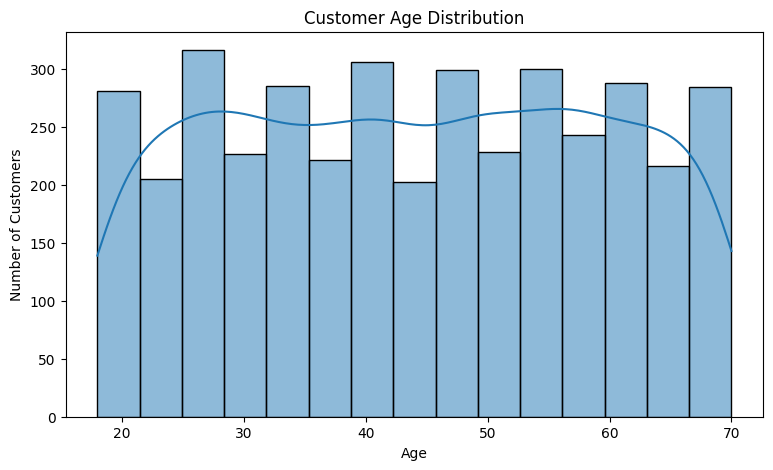

In [10]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x='age', bins=15, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

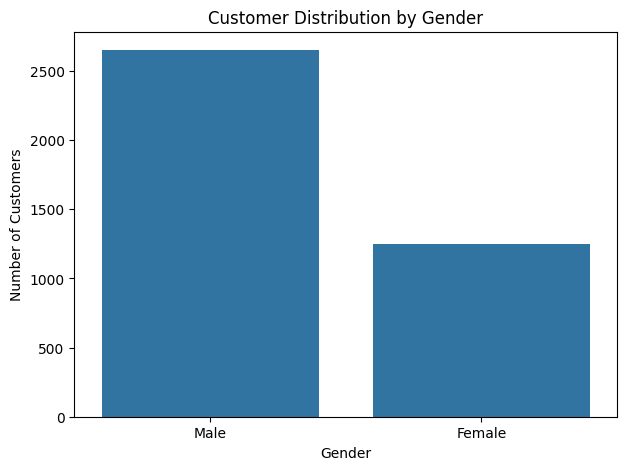

In [11]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x='gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

In [12]:
gender_spending = df_clean.groupby('gender')[
    'purchase_amount_usd'
].agg(['count', 'mean', 'sum'])

display(gender_spending)

,count,mean,sum
gender,,,
Female,1248,60.249199,75191
Male,2652,59.536199,157890


age_group
18-25    60.647986
26-35    59.760108
36-45    59.305898
46-55    60.583001
56-70    59.055204
Name: purchase_amount_usd, dtype: float64

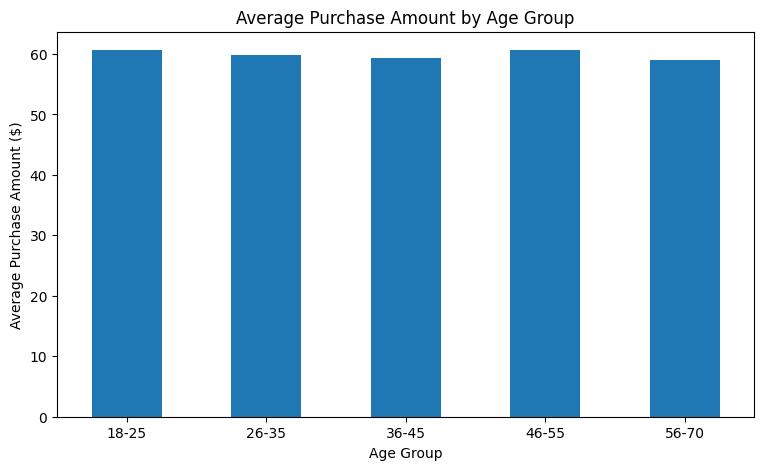

In [13]:
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[17, 25, 35, 45, 55, 70],
    labels=['18-25', '26-35', '36-45', '46-55', '56-70']
)

age_spending = df_clean.groupby(
    'age_group', observed=False
)['purchase_amount_usd'].mean()

display(age_spending)

age_spending.plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Purchase Amount by Age Group'
)

plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount ($)')
plt.xticks(rotation=0)
plt.show()

category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

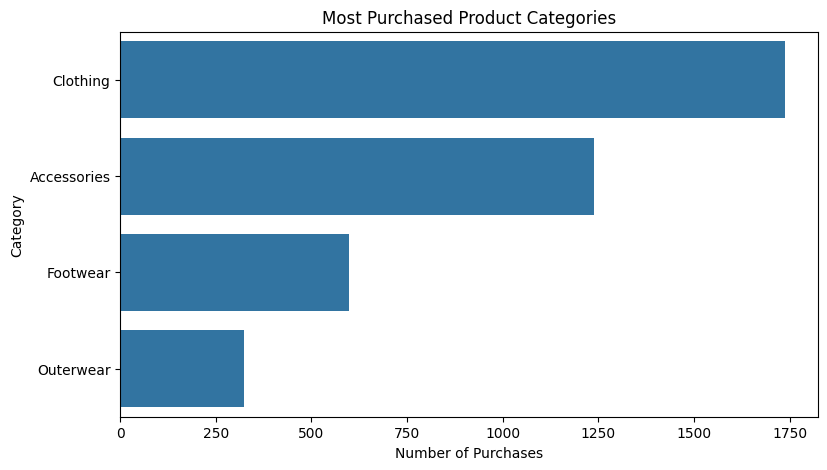

In [21]:
category_count = df_clean['category'].value_counts()

display(category_count)

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df_clean,
    y='category',
    order=category_count.index
)

plt.title('Most Purchased Product Categories')
plt.xlabel('Number of Purchases')
plt.ylabel('Category')
plt.show()

,sum,mean,count
category,,,
Clothing,104264,60.025331,1737
Accessories,74200,59.838710,1240
Footwear,36093,60.255426,599
Outerwear,18524,57.172840,324


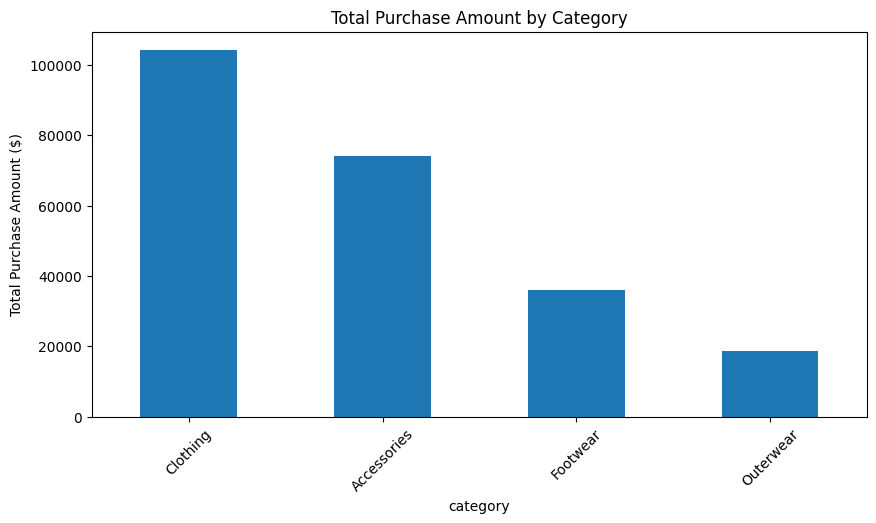

In [51]:
category_revenue = df_clean.groupby(
    'category'
)['purchase_amount_usd'].agg(['sum', 'mean', 'count'])

category_revenue = category_revenue.sort_values(
    by='sum', ascending=False
)

display(category_revenue)

category_revenue['sum'].plot(
    kind='bar',
    figsize=(10, 5),
    title='Total Purchase Amount by Category',
    ylabel='Total Purchase Amount ($)'
)

plt.xticks(rotation=45)
plt.show()

In [6]:
import pandas as pd

df_clean = pd.read_csv(
    '/kaggle/input/datasets/iamsouravbanerjee/customer-shopping-trends-dataset/shopping_trends_updated.csv'
)

df_clean.columns = (
    df_clean.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace(r'[^a-z0-9_]', '', regex=True)
)

print("DATASET LOADED:", df_clean.shape)
print(df_clean.head())

DATASET LOADED: (3900, 18)
   customer_id  age gender item_purchased  category  purchase_amount_usd  \
0            1   55   Male         Blouse  Clothing                   53   
1            2   19   Male        Sweater  Clothing                   64   
2            3   50   Male          Jeans  Clothing                   73   
3            4   21   Male        Sandals  Footwear                   90   
4            5   45   Male         Blouse  Clothing                   49   

        location size      color  season  review_rating subscription_status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

   shipping_type discount_applied promo_c

In [7]:
popular_items = df_clean['item_purchased'].value_counts()
display(popular_items.head(10))

item_purchased
Blouse        171
Pants         171
Jewelry       171
Shirt         169
Dress         166
Sweater       164
Jacket        163
Coat          161
Sunglasses    161
Belt          161
Name: count, dtype: int64

discount_applied
No     2223
Yes    1677
Name: count, dtype: int64

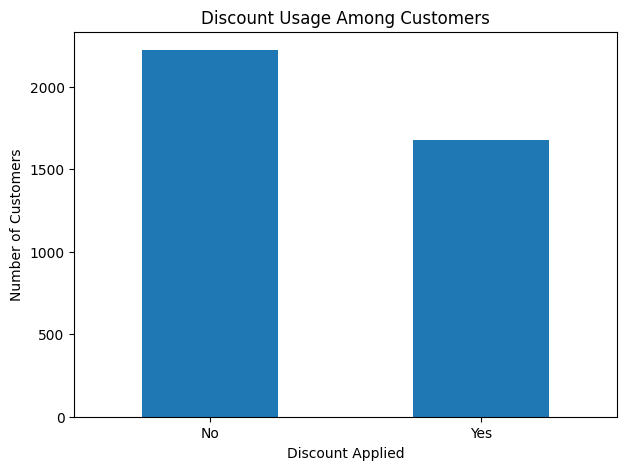

In [8]:
discount_analysis = df_clean['discount_applied'].value_counts()

display(discount_analysis)

discount_analysis.plot(
    kind='bar',
    figsize=(7, 5),
    title='Discount Usage Among Customers'
)

plt.xlabel('Discount Applied')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [9]:
subscription_analysis = df_clean.groupby(
    'subscription_status'
)['purchase_amount_usd'].agg(['count', 'mean', 'sum'])

display(subscription_analysis)

,count,mean,sum
subscription_status,,,
No,2847,59.865121,170436
Yes,1053,59.491928,62645


discount_applied
No     60.130454
Yes    59.279070
Name: purchase_amount_usd, dtype: float64

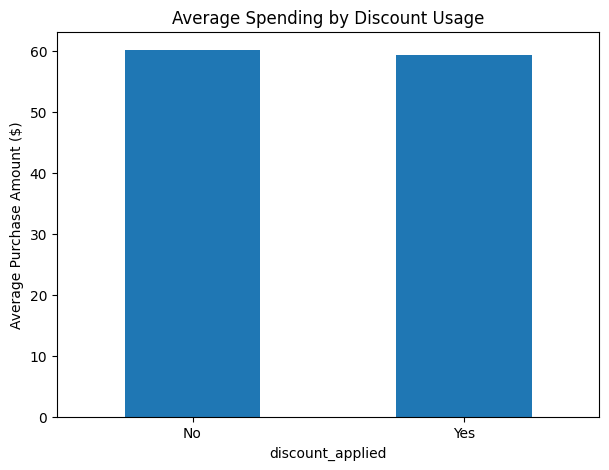

In [10]:
discount_spending = df_clean.groupby(
    'discount_applied'
)['purchase_amount_usd'].mean()

display(discount_spending)

discount_spending.plot(
    kind='bar',
    figsize=(7, 5),
    title='Average Spending by Discount Usage'
)

plt.ylabel('Average Purchase Amount ($)')
plt.xticks(rotation=0)
plt.show()

payment_method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64

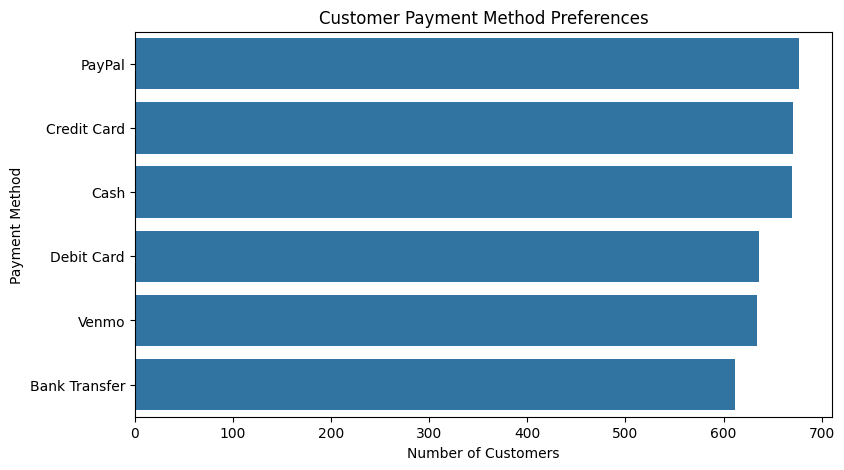

In [11]:
payment_analysis = df_clean['payment_method'].value_counts()

display(payment_analysis)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=payment_analysis.values,
    y=payment_analysis.index
)

plt.title('Customer Payment Method Preferences')
plt.xlabel('Number of Customers')
plt.ylabel('Payment Method')
plt.show()

In [12]:
payment_spending = df_clean.groupby(
    'payment_method'
)['purchase_amount_usd'].agg(['count', 'mean', 'sum'])

display(payment_spending.sort_values('mean', ascending=False))

,count,mean,sum
payment_method,,,
Debit Card,636,60.915094,38742
Credit Card,671,60.074516,40310
Bank Transfer,612,59.712418,36544
Cash,670,59.704478,40002
PayPal,677,59.245199,40109
Venmo,634,58.949527,37374


shipping_type
Free Shipping     675
Standard          654
Store Pickup      650
Next Day Air      648
Express           646
2-Day Shipping    627
Name: count, dtype: int64

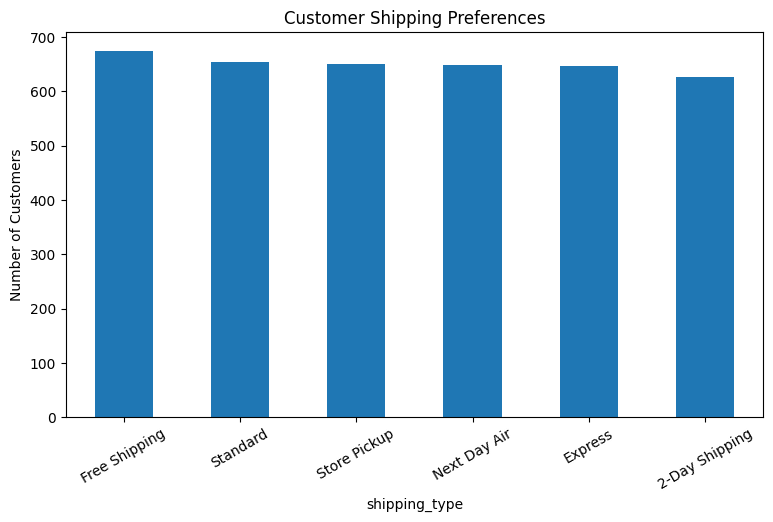

In [13]:
shipping_analysis = df_clean['shipping_type'].value_counts()

display(shipping_analysis)

shipping_analysis.plot(
    kind='bar',
    figsize=(9, 5),
    title='Customer Shipping Preferences',
    ylabel='Number of Customers'
)

plt.xticks(rotation=30)
plt.show()

frequency_of_purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539
Name: count, dtype: int64

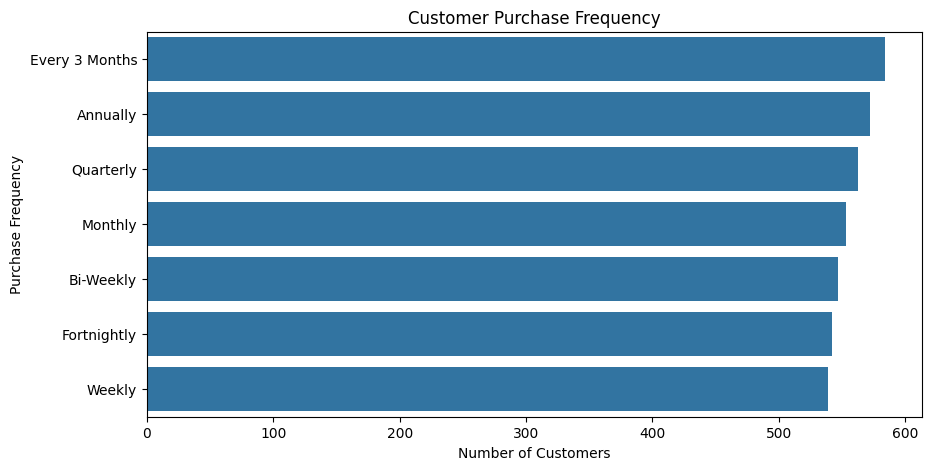

In [14]:
frequency_analysis = df_clean['frequency_of_purchases'].value_counts()

display(frequency_analysis)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=frequency_analysis.values,
    y=frequency_analysis.index
)

plt.title('Customer Purchase Frequency')
plt.xlabel('Number of Customers')
plt.ylabel('Purchase Frequency')
plt.show()

category
Footwear       3.790651
Accessories    3.768629
Outerwear      3.746914
Clothing       3.723143
Name: review_rating, dtype: float64

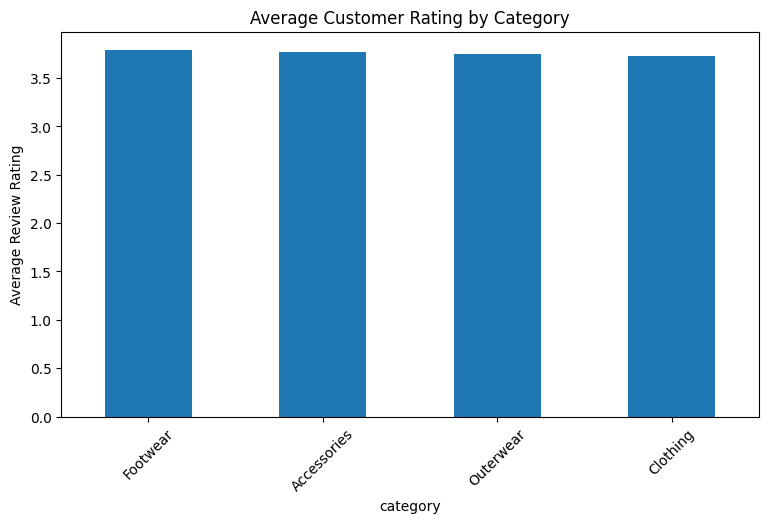

In [15]:
rating_analysis = df_clean.groupby(
    'category'
)['review_rating'].mean().sort_values(ascending=False)

display(rating_analysis)

rating_analysis.plot(
    kind='bar',
    figsize=(9, 5),
    title='Average Customer Rating by Category',
    ylabel='Average Review Rating'
)

plt.xticks(rotation=45)
plt.show()

In [16]:
!pip install duckdb

In [17]:
import duckdb

con = duckdb.connect()

con.register('customers', df_clean)

print("SQL connection established successfully!")

SQL connection established successfully!


In [18]:
con.execute("""
SELECT
    COUNT(*) AS total_customers,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    ROUND(SUM(purchase_amount_usd), 2) AS total_purchase_amount
FROM customers;
""").df()

,total_customers,average_spending,total_purchase_amount
0,3900,59.76,233081.0


In [19]:
con.execute("""
SELECT
    category,
    COUNT(*) AS total_purchases,
    SUM(purchase_amount_usd) AS total_sales,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending
FROM customers
GROUP BY category
ORDER BY total_sales DESC;
""").df()

,category,total_purchases,total_sales,average_spending
0,Clothing,1737,104264.0,60.03
1,Accessories,1240,74200.0,59.84
2,Footwear,599,36093.0,60.26
3,Outerwear,324,18524.0,57.17


In [20]:
con.execute("""
SELECT
    CASE
        WHEN age BETWEEN 18 AND 25 THEN '18-25'
        WHEN age BETWEEN 26 AND 35 THEN '26-35'
        WHEN age BETWEEN 36 AND 45 THEN '36-45'
        WHEN age BETWEEN 46 AND 55 THEN '46-55'
        ELSE '56-70'
    END AS age_group,
    COUNT(*) AS total_customers,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    SUM(purchase_amount_usd) AS total_sales
FROM customers
GROUP BY age_group
ORDER BY age_group;
""").df()

,age_group,total_customers,average_spending,total_sales
0,18-25,571,60.65,34630.0
1,26-35,742,59.76,44342.0
2,36-45,729,59.31,43234.0
3,46-55,753,60.58,45619.0
4,56-70,1105,59.06,65256.0


In [21]:
con.execute("""
SELECT
    payment_method,
    COUNT(*) AS customer_count,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    SUM(purchase_amount_usd) AS total_sales
FROM customers
GROUP BY payment_method
ORDER BY customer_count DESC;
""").df()

,payment_method,customer_count,average_spending,total_sales
0,PayPal,677,59.25,40109.0
1,Credit Card,671,60.07,40310.0
2,Cash,670,59.70,40002.0
3,Debit Card,636,60.92,38742.0
4,Venmo,634,58.95,37374.0
5,Bank Transfer,612,59.71,36544.0


In [22]:
con.execute("""
SELECT
    shipping_type,
    COUNT(*) AS customer_count,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    SUM(purchase_amount_usd) AS total_sales
FROM customers
GROUP BY shipping_type
ORDER BY customer_count DESC;
""").df()

,shipping_type,customer_count,average_spending,total_sales
0,Free Shipping,675,60.41,40777.0
1,Standard,654,58.46,38233.0
2,Store Pickup,650,59.89,38931.0
3,Next Day Air,648,58.63,37993.0
4,Express,646,60.48,39067.0
5,2-Day Shipping,627,60.73,38080.0


In [23]:
con.execute("""
SELECT
    discount_applied,
    COUNT(*) AS customer_count,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    SUM(purchase_amount_usd) AS total_sales
FROM customers
GROUP BY discount_applied;
""").df()

,discount_applied,customer_count,average_spending,total_sales
0,Yes,1677,59.28,99411.0
1,No,2223,60.13,133670.0


In [24]:
con.execute("""
SELECT
    subscription_status,
    COUNT(*) AS customer_count,
    ROUND(AVG(purchase_amount_usd), 2) AS average_spending,
    SUM(purchase_amount_usd) AS total_sales
FROM customers
GROUP BY subscription_status;
""").df()

,subscription_status,customer_count,average_spending,total_sales
0,No,2847,59.87,170436.0
1,Yes,1053,59.49,62645.0


In [26]:
# Customer shopping behavior KPI report

total_customers = len(df_clean)

total_sales = df_clean['purchase_amount_usd'].sum()

average_spending = df_clean['purchase_amount_usd'].mean()

average_rating = df_clean['review_rating'].mean()

subscription_rate = (
    df_clean['subscription_status'].eq('Yes').mean() * 100
)

discount_rate = (
    df_clean['discount_applied'].eq('Yes').mean() * 100
)

print("CUSTOMER SHOPPING BEHAVIOR KPI REPORT")
print("------------------------------------")
print("Total Customers:", total_customers)
print("Total Purchase Amount: $", round(total_sales, 2))
print("Average Spending: $", round(average_spending, 2))
print("Average Review Rating:", round(average_rating, 2))
print("Subscription Rate:", round(subscription_rate, 2), "%")
print("Discount Usage Rate:", round(discount_rate, 2), "%")

CUSTOMER SHOPPING BEHAVIOR KPI REPORT
------------------------------------
Total Customers: 3900
Total Purchase Amount: $ 233081
Average Spending: $ 59.76
Average Review Rating: 3.75
Subscription Rate: 27.0 %
Discount Usage Rate: 43.0 %


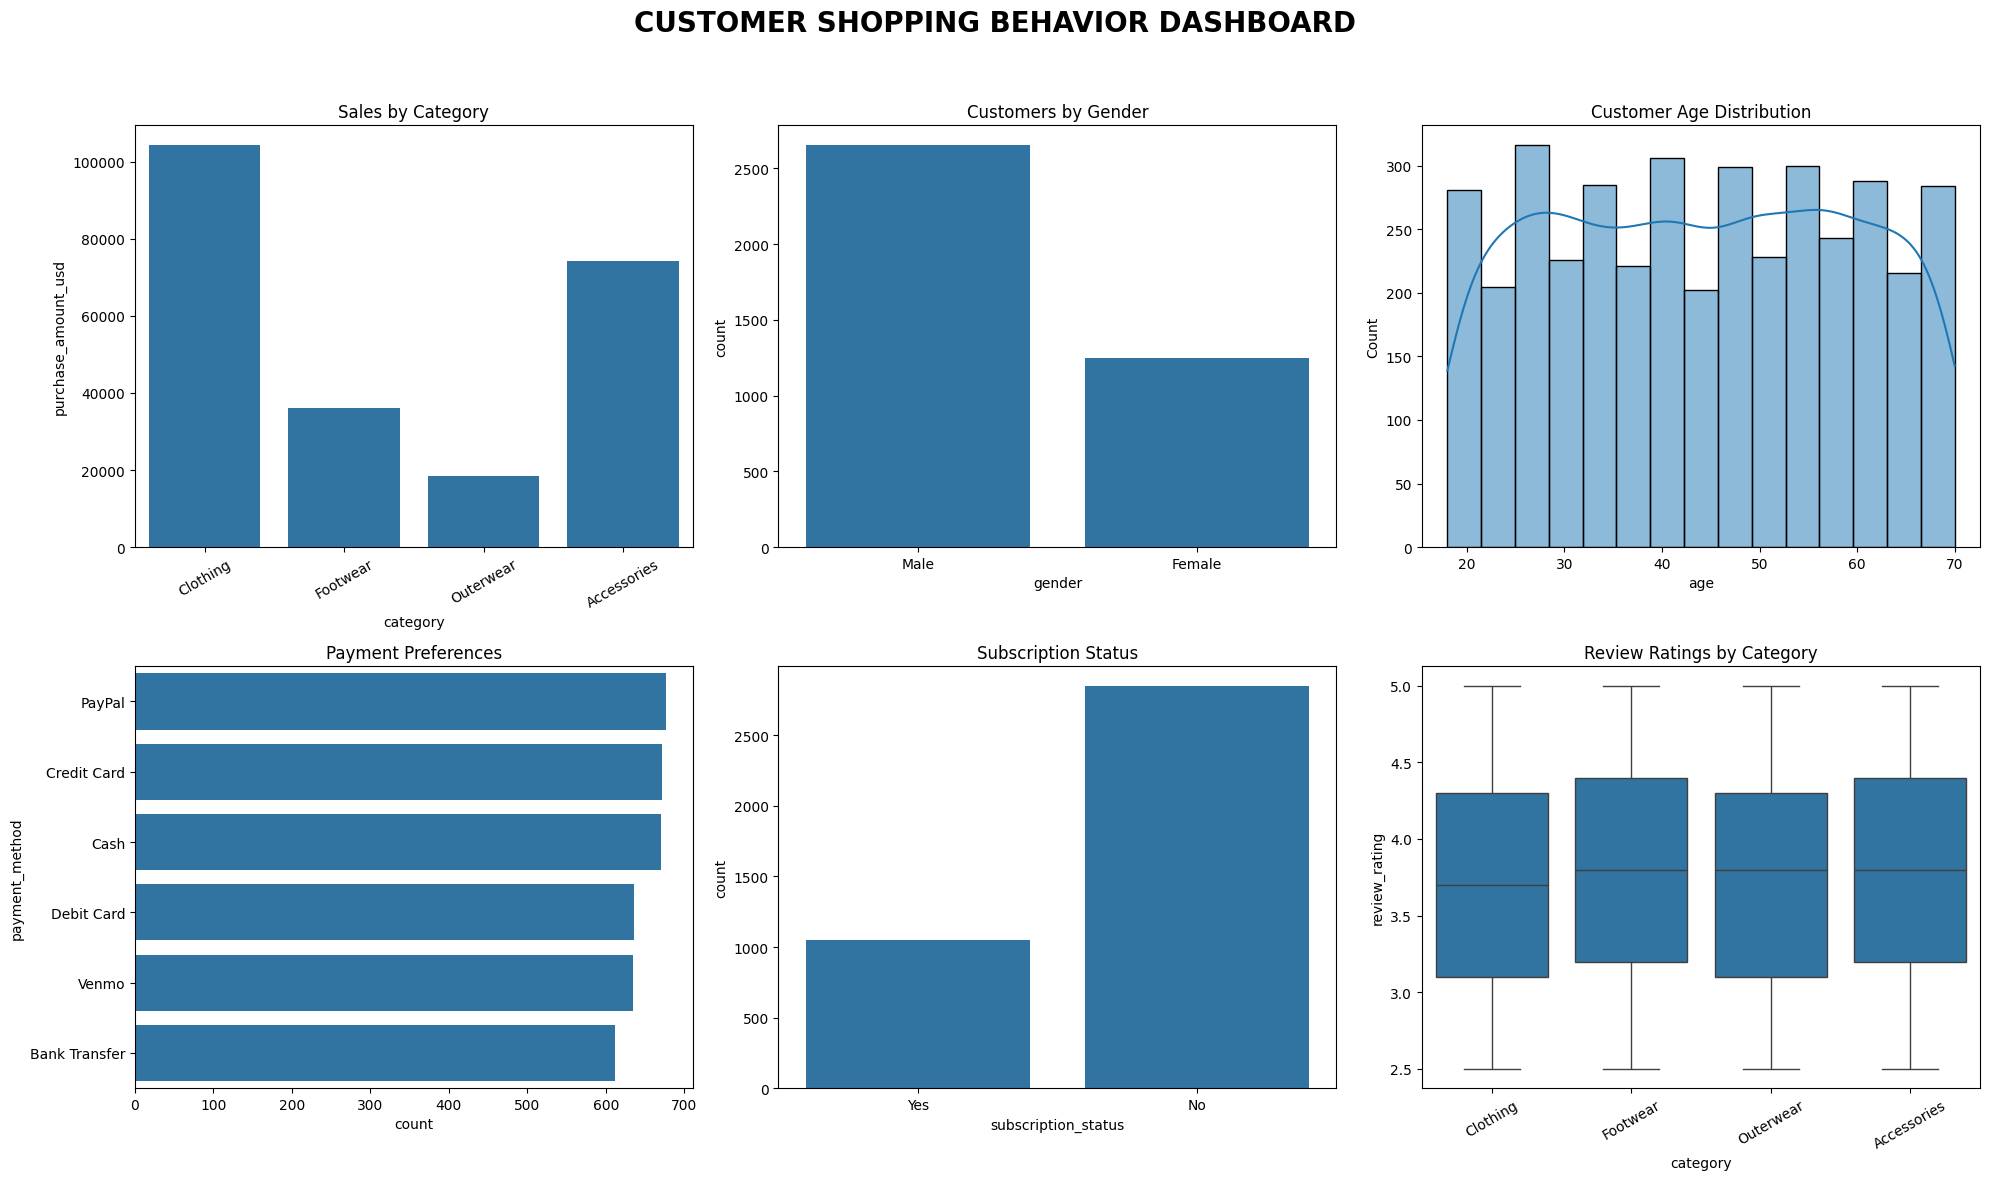

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

fig.suptitle(
    'CUSTOMER SHOPPING BEHAVIOR DASHBOARD',
    fontsize=20,
    fontweight='bold'
)

# 1. Category sales
sns.barplot(
    data=df_clean,
    x='category',
    y='purchase_amount_usd',
    estimator=sum,
    errorbar=None,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Sales by Category')
axes[0, 0].tick_params(axis='x', rotation=30)

# 2. Gender distribution
sns.countplot(
    data=df_clean,
    x='gender',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Customers by Gender')

# 3. Age distribution
sns.histplot(
    data=df_clean,
    x='age',
    bins=15,
    kde=True,
    ax=axes[0, 2]
)
axes[0, 2].set_title('Customer Age Distribution')

# 4. Payment methods
sns.countplot(
    data=df_clean,
    y='payment_method',
    order=df_clean['payment_method'].value_counts().index,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Payment Preferences')

# 5. Subscription status
sns.countplot(
    data=df_clean,
    x='subscription_status',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Subscription Status')

# 6. Review ratings
sns.boxplot(
    data=df_clean,
    x='category',
    y='review_rating',
    ax=axes[1, 2]
)
axes[1, 2].set_title('Review Ratings by Category')
axes[1, 2].tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    'customer_shopping_dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Business Insights and Recommendations

## Key Findings
- Clothing is the highest-performing category by total purchase amount.
- Accessories is the second-largest category.
- PayPal is the most frequently used payment method.
- Only 27% of customers have subscriptions.
- Discount usage is observed in 43% of customer records.
- The overall average review rating is 3.75 out of 5.

## Business Recommendations
1. Focus marketing efforts on high-performing product categories.
2. Investigate opportunities to increase customer subscriptions.
3. Evaluate customer preferences across payment methods.
4. Review customer feedback to identify product improvements.
5. Evaluate discount campaigns to understand their relationship with spending.

## Project Conclusion
This analysis uses Python, Pandas, SQL, and data visualisation
to understand customer shopping patterns and provide
data-driven business recommendations.